# 02 — FRED Macro Controls

Этот ноутбук собирает макроэкономические и финансовые control variables из **FRED** для Oil News Graph.

Главная задача controls — отделить реакцию WTI calendar spread на нефтяную информацию от общего рыночного движения.

Собираем два блока:

### Daily market / macro-financial controls
- broad U.S. dollar index;
- VIX;
- effective federal funds rate;
- 2Y и 10Y Treasury yields;
- 10Y−2Y yield curve;
- 10Y real yield;
- 10Y breakeven inflation;
- Baa credit spread.

### Monthly macro state
- CPI;
- industrial production;
- unemployment.

Для monthly series дополнительно сохраняем **initial-release observations** (`output_type=4`) для будущей point-in-time сборки без revision leakage.

> В `.env` в корне проекта:
>
> `FRED_API_KEY=...`


## 1. Окружение

Проект использует `uv` и Python 3.12. Kernel должен быть из `.venv`.


In [1]:
import sys

print(sys.version)
print(sys.executable)

assert sys.version_info[:2] == (3, 12)
assert ".venv" in sys.executable


3.12.16 (main, Oct 26 2026, 13:59:40) [Clang 23.1.3 ]
/Users/ivanandreev/Desktop/ИИ/Нефть/oil-news-graph/.venv/bin/python


## 2. Корень проекта и каталоги


In [2]:
import logging
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd


def find_project_root(start: Path | None = None) -> Path:
    current = (start or Path.cwd()).resolve()

    for candidate in [current, *current.parents]:
        if (candidate / "src").exists() and (candidate / "pyproject.toml").exists():
            return candidate

    raise FileNotFoundError(
        "Не удалось найти корень проекта с src/ и pyproject.toml."
    )


ROOT = find_project_root()

if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

RAW_DIR = ROOT / "data" / "raw" / "fred"
PROCESSED_DIR = ROOT / "data" / "processed" / "fred"

RAW_DIR.mkdir(parents=True, exist_ok=True)
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

logging.basicConfig(
    level=logging.INFO,
    format="%(levelname)s | %(message)s",
)

print("Project root:", ROOT)
print("FRED raw dir:", RAW_DIR)


Project root: /Users/ivanandreev/Desktop/ИИ/Нефть/oil-news-graph
FRED raw dir: /Users/ivanandreev/Desktop/ИИ/Нефть/oil-news-graph/data/raw/fred


## 3. FRED client


In [3]:
from src.data.fred_client import (
    FRED_DAILY_CONTROLS,
    FRED_MONTHLY_CONTROLS,
    FredClient,
)

client = FredClient()
client.test_connection()


True

## 4. Период

Используем тот же старт, что и в основном проекте: 2015-02-19.


In [4]:
START_DATE = "2015-02-19"
END_DATE = "2026-11-04"


# 5. Проверка конфигурации controls

Daily controls — основной блок для будущего event study вокруг EIA releases.


In [5]:
daily_config = pd.DataFrame(
    [
        {
            "name": name,
            "series_id": spec.series_id,
            "description": spec.description,
        }
        for name, spec in FRED_DAILY_CONTROLS.items()
    ]
)

daily_config


,name,series_id,description
0,usd_broad,DTWEXBGS,Nominal Broad U.S. Dollar Index
1,vix,VIXCLS,CBOE Volatility Index
2,fed_funds,DFF,Federal Funds Effective Rate
3,treasury_2y,DGS2,2-Year Treasury Constant Maturity Rate
4,treasury_10y,DGS10,10-Year Treasury Constant Maturity Rate
5,yield_curve_10y2y,T10Y2Y,10-Year Treasury Minus 2-Year Treasury
6,real_yield_10y,DFII10,10-Year Treasury Inflation-Indexed Yield
7,breakeven_10y,T10YIE,10-Year Breakeven Inflation Rate
8,baa_spread,BAA10Y,Baa Corporate Bond Yield Minus 10-Year Treasury


In [6]:
monthly_config = pd.DataFrame(
    [
        {
            "name": name,
            "series_id": spec.series_id,
            "description": spec.description,
        }
        for name, spec in FRED_MONTHLY_CONTROLS.items()
    ]
)

monthly_config


,name,series_id,description
0,cpi,CPIAUCSL,Consumer Price Index for All Urban Consumers
1,industrial_production,INDPRO,Industrial Production: Total Index
2,unemployment,UNRATE,Unemployment Rate


## 6. Sanity check metadata

Проверяем реальные metadata FRED, а не только наши подписи.


In [7]:
metadata_rows = []

for name, spec in {
    **FRED_DAILY_CONTROLS,
    **FRED_MONTHLY_CONTROLS,
}.items():
    info = client.get_series_info(spec.series_id)

    metadata_rows.append(
        {
            "name": name,
            "series_id": spec.series_id,
            "title": info.get("title"),
            "frequency": info.get("frequency"),
            "units": info.get("units"),
            "observation_start": info.get("observation_start"),
            "observation_end": info.get("observation_end"),
            "last_updated": info.get("last_updated"),
        }
    )

metadata = pd.DataFrame(metadata_rows)
metadata


,name,series_id,title,frequency,units,observation_start,observation_end,last_updated
0,usd_broad,DTWEXBGS,Nominal Broad U.S. Dollar Index,Daily,Index Jan 2006=100,2006-01-02,2026-10-30,2026-11-02 15:51:35-06
1,vix,VIXCLS,CBOE Volatility Index: VIX,"Daily, Close",Index,1990-01-02,2026-11-03,2026-11-04 08:37:31-06
2,fed_funds,DFF,Federal Funds Effective Rate,"Daily, 7-Day",Percent,1954-07-01,2026-11-02,2026-11-03 15:16:31-06
3,treasury_2y,DGS2,Market Yield on U.S. Treasury Securities at 2-...,Daily,Percent,1976-06-01,2026-11-02,2026-11-03 15:16:27-06
4,treasury_10y,DGS10,Market Yield on U.S. Treasury Securities at 10...,Daily,Percent,1962-01-02,2026-11-02,2026-11-03 15:16:31-06
5,yield_curve_10y2y,T10Y2Y,10-Year Treasury Constant Maturity Minus 2-Yea...,Daily,Percent,1976-06-01,2026-11-03,2026-11-03 16:02:33-06
6,real_yield_10y,DFII10,Market Yield on U.S. Treasury Securities at 10...,Daily,Percent,2003-01-02,2026-11-02,2026-11-03 15:16:27-06
7,breakeven_10y,T10YIE,10-Year Breakeven Inflation Rate,Daily,Percent,2003-01-02,2026-11-03,2026-11-03 16:03:26-06
8,baa_spread,BAA10Y,Moody's Seasoned Baa Corporate Bond Yield Rela...,Daily,Percent,1986-01-02,2026-11-02,2026-11-03 16:02:32-06
9,cpi,CPIAUCSL,Consumer Price Index for All Urban Consumers: ...,Monthly,Index 1982-1984=100,1947-01-01,2026-09-01,2026-10-14 08:08:29-05


# 7. Daily controls

Скачиваем daily series в wide-формате. Не forward-fill'им здесь пропуски: точное выравнивание будет сделано позже по EIA `release_datetime` через as-of logic.


In [8]:
daily = client.fetch_many(
    FRED_DAILY_CONTROLS,
    start=START_DATE,
    end=END_DATE,
)

daily.head()


INFO | Downloading usd_broad (DTWEXBGS)
INFO | Downloading vix (VIXCLS)
INFO | Downloading fed_funds (DFF)
INFO | Downloading treasury_2y (DGS2)
INFO | Downloading treasury_10y (DGS10)
INFO | Downloading yield_curve_10y2y (T10Y2Y)
INFO | Downloading real_yield_10y (DFII10)
INFO | Downloading breakeven_10y (T10YIE)
INFO | Downloading baa_spread (BAA10Y)


,date,usd_broad,vix,fed_funds,treasury_2y,treasury_10y,yield_curve_10y2y,real_yield_10y,breakeven_10y,baa_spread
0,2015-02-19,105.1407,15.29,0.12,0.67,2.11,1.44,0.37,1.74,2.53
1,2015-02-20,105.3387,14.30,0.12,0.67,2.13,1.46,0.38,1.75,2.50
2,2015-02-21,NaN,NaN,0.12,NaN,NaN,NaN,NaN,NaN,NaN
3,2015-02-22,NaN,NaN,0.12,NaN,NaN,NaN,NaN,NaN,NaN
4,2015-02-23,105.5359,14.56,0.11,0.64,2.06,1.42,0.34,1.72,2.48


In [9]:
print("Shape:", daily.shape)
print("Period:", daily["date"].min(), "->", daily["date"].max())

daily.isna().sum().sort_values(ascending=False)


Shape: (4276, 10)
Period: 2015-02-19 00:00:00 -> 2026-11-03 00:00:00


usd_broad            1357
baa_spread           1353
treasury_2y          1348
treasury_10y         1348
real_yield_10y       1348
yield_curve_10y2y    1347
breakeven_10y        1347
vix                  1298
fed_funds               1
date                    0
dtype: int64

## 7.1 Почему в daily controls есть пропуски

Это ожидаемо: ряды используют разные календари.

- `DFF` публикуется 7 дней в неделю.
- Treasury yields, VIX, dollar index и credit spreads живут на рыночном / рабочем календаре.
- На выходных и праздниках часть market series не имеет нового значения.
- В конце выборки возможны пропуски из-за лагов публикации.

Поэтому raw-таблицу не заполняем искусственно.

Для производных признаков ниже считаем изменения между **последовательными ненулевыми наблюдениями**, а не между соседними календарными строками.


In [10]:
missing_diagnostic = pd.DataFrame(
    {
        "missing": daily.isna().sum(),
        "missing_pct_all_calendar_rows": (
            daily.isna().mean() * 100
        ).round(2),
    }
).sort_values(
    "missing_pct_all_calendar_rows",
    ascending=False,
)

missing_diagnostic


,missing,missing_pct_all_calendar_rows
usd_broad,1357,31.74
baa_spread,1353,31.64
treasury_2y,1348,31.52
treasury_10y,1348,31.52
real_yield_10y,1348,31.52
yield_curve_10y2y,1347,31.50
breakeven_10y,1347,31.50
vix,1298,30.36
fed_funds,1,0.02
date,0,0.00


## 8. Daily derived features

Сохраняем и уровни, и краткосрочные изменения.

- USD — процентное изменение индекса;
- VIX — изменение пунктов;
- ставки и spreads — изменение в basis points (`1% = 100 bp`).

Эти features потом будут лагированы / взяты as-of непосредственно перед EIA release.


In [11]:
daily_features = daily.copy()


def observed_diff(series: pd.Series, periods: int = 1) -> pd.Series:
    observed = series.dropna()
    return observed.diff(periods).reindex(series.index)


def observed_pct_change(
    series: pd.Series,
    periods: int = 1,
) -> pd.Series:
    observed = series.dropna()
    return observed.pct_change(
        periods=periods,
        fill_method=None,
    ).reindex(series.index)


if "usd_broad" in daily_features:
    daily_features["usd_broad_return_1obs_pct"] = (
        observed_pct_change(daily_features["usd_broad"]) * 100
    )

if "vix" in daily_features:
    daily_features["vix_change_1obs"] = observed_diff(
        daily_features["vix"]
    )

RATE_COLUMNS = [
    "fed_funds",
    "treasury_2y",
    "treasury_10y",
    "yield_curve_10y2y",
    "real_yield_10y",
    "breakeven_10y",
    "baa_spread",
]

for col in RATE_COLUMNS:
    if col in daily_features:
        daily_features[f"{col}_change_1obs_bp"] = (
            observed_diff(daily_features[col]) * 100
        )

daily_features.tail()


,date,usd_broad,vix,fed_funds,treasury_2y,treasury_10y,yield_curve_10y2y,real_yield_10y,breakeven_10y,baa_spread,usd_broad_return_1obs_pct,vix_change_1obs,fed_funds_change_1obs_bp,treasury_2y_change_1obs_bp,treasury_10y_change_1obs_bp,yield_curve_10y2y_change_1obs_bp,real_yield_10y_change_1obs_bp,breakeven_10y_change_1obs_bp,baa_spread_change_1obs_bp
4271,2026-10-30,121.6656,19.42,3.88,4.56,4.94,0.38,2.60,2.34,1.53,-0.057912,2.22,0.0,-5.0,-4.0,1.0,-3.0,-1.0,4.0
4272,2026-10-31,NaN,NaN,3.88,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN
4273,2026-11-01,NaN,NaN,3.88,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN
4274,2026-11-02,NaN,21.15,3.88,4.59,4.91,0.32,2.62,2.29,1.53,NaN,1.73,0.0,3.0,-3.0,-6.0,2.0,-5.0,0.0
4275,2026-11-03,NaN,20.83,NaN,NaN,NaN,0.34,NaN,2.30,NaN,NaN,-0.32,NaN,NaN,NaN,2.0,NaN,1.0,NaN


## 9. 5-business-day changes

Для weekly модели полезен не только последний день, но и движение макрофакторов за несколько торговых дней.


In [12]:
if "usd_broad" in daily_features:
    daily_features["usd_broad_return_5obs_pct"] = (
        observed_pct_change(
            daily_features["usd_broad"],
            periods=5,
        )
        * 100
    )

if "vix" in daily_features:
    daily_features["vix_change_5obs"] = observed_diff(
        daily_features["vix"],
        periods=5,
    )

for col in RATE_COLUMNS:
    if col in daily_features:
        daily_features[f"{col}_change_5obs_bp"] = (
            observed_diff(
                daily_features[col],
                periods=5,
            )
            * 100
        )

daily_features.tail()


,date,usd_broad,vix,fed_funds,treasury_2y,treasury_10y,yield_curve_10y2y,real_yield_10y,breakeven_10y,baa_spread,...,baa_spread_change_1obs_bp,usd_broad_return_5obs_pct,vix_change_5obs,fed_funds_change_5obs_bp,treasury_2y_change_5obs_bp,treasury_10y_change_5obs_bp,yield_curve_10y2y_change_5obs_bp,real_yield_10y_change_5obs_bp,breakeven_10y_change_5obs_bp,baa_spread_change_5obs_bp
4271,2026-10-30,121.6656,19.42,3.88,4.56,4.94,0.38,2.60,2.34,1.53,...,4.0,0.284701,-0.03,0.0,-13.0,-6.0,7.0,-6.0,0.0,6.0
4272,2026-10-31,NaN,NaN,3.88,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN
4273,2026-11-01,NaN,NaN,3.88,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN
4274,2026-11-02,NaN,21.15,3.88,4.59,4.91,0.32,2.62,2.29,1.53,...,0.0,NaN,2.76,0.0,-9.0,-9.0,0.0,-4.0,-5.0,8.0
4275,2026-11-03,NaN,20.83,NaN,NaN,NaN,0.34,NaN,2.30,NaN,...,NaN,NaN,3.31,NaN,NaN,NaN,5.0,NaN,-5.0,NaN


## 10. Быстрый график ключевых market controls


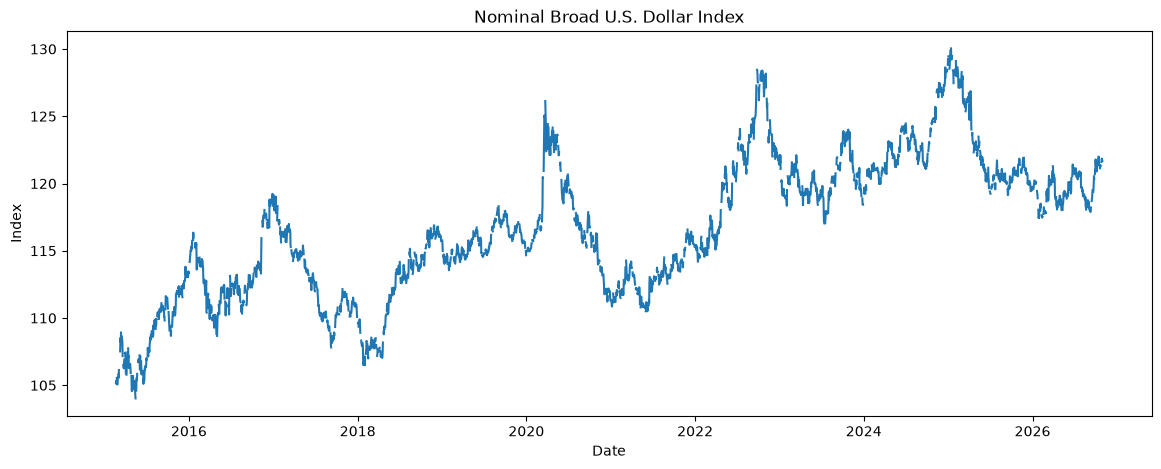

In [13]:
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(daily_features["date"], daily_features["usd_broad"])
ax.set_title("Nominal Broad U.S. Dollar Index")
ax.set_xlabel("Date")
ax.set_ylabel("Index")
plt.show()


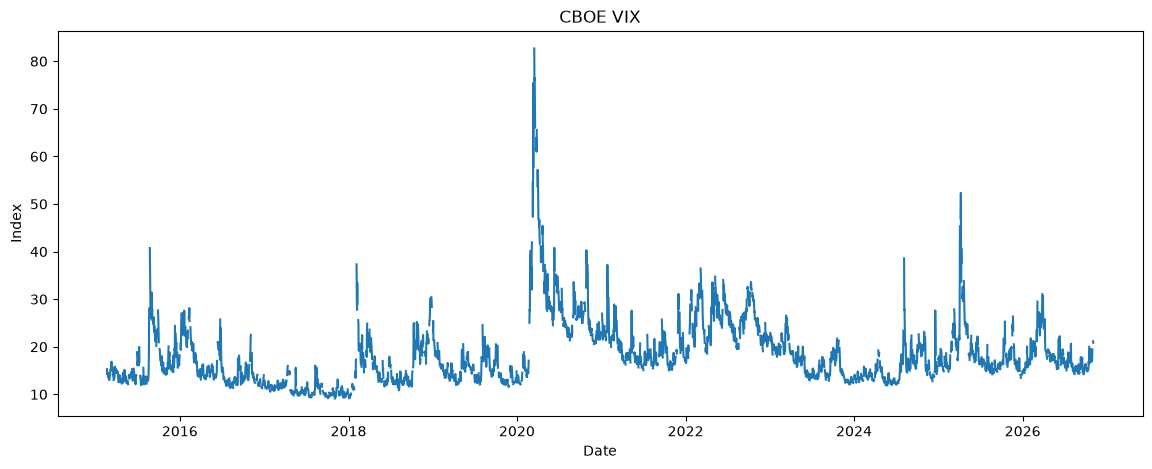

In [14]:
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(daily_features["date"], daily_features["vix"])
ax.set_title("CBOE VIX")
ax.set_xlabel("Date")
ax.set_ylabel("Index")
plt.show()


# 11. Monthly macro state — current revised history

Эта таблица полезна для EDA, но **не считается model-ready**, потому что исторические monthly values могут быть пересмотрены.


In [15]:
monthly_current = client.fetch_many(
    FRED_MONTHLY_CONTROLS,
    start=START_DATE,
    end=END_DATE,
)

monthly_current.tail()


INFO | Downloading cpi (CPIAUCSL)
INFO | Downloading industrial_production (INDPRO)
INFO | Downloading unemployment (UNRATE)


,date,cpi,industrial_production,unemployment
135,2026-05-01,333.979,102.7232,4.3
136,2026-06-01,332.568,102.9610,4.2
137,2026-07-01,332.813,103.2006,4.1
138,2026-08-01,334.131,103.2664,4.1
139,2026-09-01,336.298,103.9506,4.2


## 12. Derived monthly macro features

Для EDA считаем CPI YoY и изменения industrial production / unemployment.

При финальном point-in-time датасете будем строить эти признаки только из информации, доступной на соответствующую дату.


In [16]:
monthly_features = monthly_current.copy()

if "cpi" in monthly_features:
    monthly_features["cpi_yoy_pct"] = (
        monthly_features["cpi"].pct_change(
            periods=12,
            fill_method=None,
        )
        * 100
    )

if "industrial_production" in monthly_features:
    monthly_features["industrial_production_yoy_pct"] = (
        monthly_features["industrial_production"].pct_change(
            periods=12,
            fill_method=None,
        )
        * 100
    )

if "unemployment" in monthly_features:
    monthly_features["unemployment_change_1m_pp"] = (
        monthly_features["unemployment"].diff()
    )

monthly_features.tail(15)


,date,cpi,industrial_production,unemployment,cpi_yoy_pct,industrial_production_yoy_pct,unemployment_change_1m_pp
125,2025-07-01,322.169,101.8940,4.3,2.742618,1.918766,0.2
126,2025-08-01,323.291,101.6247,4.3,2.938592,1.188678,0.0
127,2025-09-01,324.245,101.6680,4.4,3.022572,1.863170,0.1
128,2025-10-01,NaN,101.2195,NaN,NaN,1.759333,NaN
129,2025-11-01,325.063,101.0344,4.5,2.696444,1.754312,NaN
130,2025-12-01,326.031,101.4941,4.4,2.653304,1.162994,-0.1
131,2026-01-01,326.588,101.0388,4.3,2.391201,0.973470,-0.1
132,2026-02-01,327.460,101.9053,4.4,2.434004,0.797236,0.1
133,2026-03-01,330.293,101.7336,4.3,3.285958,0.686062,-0.1
134,2026-04-01,332.407,102.5768,4.3,3.779246,1.432740,0.0


# 13. Monthly macro state — initial releases

Для monthly macro важно избежать revision leakage.

`fred/series/observations` по умолчанию использует real-time period = **сегодня**.
Для `output_type=4` исправленный клиент теперь автоматически задаёт широкий исторический real-time interval и получает **initial release only**.

Сохраняем `realtime_start`: позже это будет дата, с которой конкретное значение стало доступно в ALFRED/FRED.


In [17]:
monthly_initial = client.fetch_many_long(
    FRED_MONTHLY_CONTROLS,
    start=START_DATE,
    end=END_DATE,
    output_type=4,
)

monthly_initial.head(15)


INFO | Downloading cpi (CPIAUCSL)
INFO | Downloading industrial_production (INDPRO)
INFO | Downloading unemployment (UNRATE)


,date,value,realtime_start,realtime_end,series_id,name,description
0,2015-02-01,235.186,2015-03-24,2016-02-18,CPIAUCSL,cpi,Consumer Price Index for All Urban Consumers
1,2015-03-01,235.740,2015-04-17,2016-02-18,CPIAUCSL,cpi,Consumer Price Index for All Urban Consumers
2,2015-04-01,235.982,2015-05-22,2016-02-18,CPIAUCSL,cpi,Consumer Price Index for All Urban Consumers
3,2015-05-01,237.031,2015-06-18,2016-02-18,CPIAUCSL,cpi,Consumer Price Index for All Urban Consumers
4,2015-06-01,237.786,2015-07-17,2016-02-18,CPIAUCSL,cpi,Consumer Price Index for All Urban Consumers
5,2015-07-01,238.099,2015-08-19,2016-02-18,CPIAUCSL,cpi,Consumer Price Index for All Urban Consumers
6,2015-08-01,237.931,2015-09-16,2016-02-18,CPIAUCSL,cpi,Consumer Price Index for All Urban Consumers
7,2015-09-01,237.566,2015-10-15,2016-02-18,CPIAUCSL,cpi,Consumer Price Index for All Urban Consumers
8,2015-10-01,238.042,2015-11-17,2016-02-18,CPIAUCSL,cpi,Consumer Price Index for All Urban Consumers
9,2015-11-01,238.111,2015-12-15,2016-02-18,CPIAUCSL,cpi,Consumer Price Index for All Urban Consumers


In [18]:
monthly_initial[
    [
        "name",
        "series_id",
        "date",
        "value",
        "realtime_start",
        "realtime_end",
    ]
].tail(20)


,name,series_id,date,value,realtime_start,realtime_end
400,unemployment,UNRATE,2025-02-01,4.1,2025-03-07,2026-01-08
401,unemployment,UNRATE,2025-03-01,4.2,2025-04-04,9999-12-31
402,unemployment,UNRATE,2025-04-01,4.2,2025-05-02,9999-12-31
403,unemployment,UNRATE,2025-05-01,4.2,2025-06-06,2026-01-08
404,unemployment,UNRATE,2025-06-01,4.1,2025-07-03,9999-12-31
405,unemployment,UNRATE,2025-07-01,4.2,2025-08-01,2026-01-08
406,unemployment,UNRATE,2025-08-01,4.3,2025-09-05,9999-12-31
407,unemployment,UNRATE,2025-09-01,4.4,2025-11-20,9999-12-31
408,unemployment,UNRATE,2025-10-01,NaN,2025-12-16,9999-12-31
409,unemployment,UNRATE,2025-11-01,4.6,2025-12-16,2026-01-08


## 14. Проверка initial-release availability

Смотрим лаг между observation date и первой доступностью в FRED/ALFRED.


In [19]:
monthly_initial["availability_lag_days"] = (
    monthly_initial["realtime_start"]
    - monthly_initial["date"]
).dt.days

monthly_initial.groupby("name")["availability_lag_days"].describe()


,count,mean,std,min,25%,50%,75%,max
name,,,,,,,,
cpi,140.0,42.707143,4.114366,37.0,40.0,42.0,44.0,78.0
industrial_production,140.0,45.964286,5.304282,42.0,44.0,45.0,46.0,93.0
unemployment,140.0,34.992857,5.740800,31.0,32.0,34.0,36.0,80.0


# 15. Почему пока не собираем weekly table

Не надо искусственно ресемплировать controls на каждую среду сейчас.

Финальная логика будет:

```text
EIA release_datetime
        ↓
для каждого control берём последнее значение,
которое было известно ДО release
```

Для daily market controls это будет предыдущий доступный market observation.

Для monthly macro — последнее observation с `realtime_start <= release date`.

Так мы избежим holiday errors и look-ahead leakage.


# 16. Data quality


In [20]:
def data_summary(df: pd.DataFrame) -> pd.DataFrame:
    return pd.DataFrame(
        {
            "dtype": df.dtypes.astype(str),
            "missing": df.isna().sum(),
            "missing_pct": (df.isna().mean() * 100).round(2),
            "n_unique": df.nunique(dropna=True),
        }
    )


data_summary(daily_features)


,dtype,missing,missing_pct,n_unique
date,datetime64[us],0,0.00,4276
usd_broad,float64,1357,31.74,2899
vix,float64,1298,30.36,1504
fed_funds,float64,1,0.02,105
treasury_2y,float64,1348,31.52,477
treasury_10y,float64,1348,31.52,444
yield_curve_10y2y,float64,1347,31.50,275
real_yield_10y,float64,1348,31.52,379
breakeven_10y,float64,1347,31.50,208
baa_spread,float64,1353,31.64,241


In [21]:
data_summary(monthly_features)


,dtype,missing,missing_pct,n_unique
date,datetime64[us],0,0.00,140
cpi,float64,1,0.71,138
industrial_production,float64,0,0.00,139
unemployment,float64,1,0.71,36
cpi_yoy_pct,float64,13,9.29,127
industrial_production_yoy_pct,float64,12,8.57,128
unemployment_change_1m_pp,float64,3,2.14,26


# 17. Сохранение

Raw:
- daily current observations;
- monthly current observations;
- monthly initial-release long history;
- metadata.

Processed:
- daily levels + 1d/5d changes;
- monthly EDA features.

Raw/processed data не должны коммититься в Git.


In [22]:
daily.to_parquet(
    RAW_DIR / "fred_daily_controls_2015_2026.parquet",
    index=False,
)
monthly_current.to_parquet(
    RAW_DIR / "fred_monthly_controls_current_2015_2026.parquet",
    index=False,
)
monthly_initial.to_parquet(
    RAW_DIR / "fred_monthly_controls_initial_2015_2026.parquet",
    index=False,
)
metadata.to_parquet(
    RAW_DIR / "fred_series_metadata.parquet",
    index=False,
)

daily_features.to_parquet(
    PROCESSED_DIR / "fred_daily_features.parquet",
    index=False,
)
monthly_features.to_parquet(
    PROCESSED_DIR / "fred_monthly_features_current.parquet",
    index=False,
)

print("FRED data saved.")


FRED data saved.


# 18. Итог

После этого FRED-блок готов для будущего master dataset.

### Core daily controls
- USD;
- VIX;
- Fed Funds;
- 2Y Treasury;
- 10Y Treasury;
- yield curve;
- real yield;
- breakeven inflation;
- credit spread.

### Slow macro state
- CPI;
- industrial production;
- unemployment.

### Следующий этап

После получения таблицы EIA `release_datetime` делаем отдельный builder:

```text
EIA release
+ latest-known FRED controls
+ consensus
+ news graph features
+ pre-release WTI spread
→ model-ready weekly dataset
```

Monthly current-revised features оставляем только для EDA. Для модели используем initial/vintage information.
